# 03 Forecast wins vs portfolio wins

**Question: do better forecasts give better portfolios?** The research question has two halves:
do macro-aware forecasts beat the historical-volatility benchmark in **forecast accuracy**, and do
those gains **translate into better risk-adjusted performance** in volatility-managed portfolios?
This notebook links the two halves. It computes no new tests:

- **Forecast side:** `models/forecasting/evaluation/e6_overall_comparison_to_benchmark.ipynb`,
  every model against `hist_rw` (Clark-West on log-RV MSE for the Elastic Net models, which nest
  `hist_rw`; Diebold-Mariano otherwise; one-sided, H1: the model beats `hist_rw`).
- **Portfolio side:** `02_eval_portfolios.ipynb`, the Ledoit-Wolf test of SR(model) − SR(`hist_rw`),
  fixed σ̄² (two-sided).

Both use the same out-of-sample months, 2008-03 to 2025-12. Run 01, 02 and e6 first. The block
pairs (B1 to B5) are compared in 02 on the portfolio side and in e2 to e5 on the forecast side.

| Section | Question |
|---|---|
| 1 Pair-level link | When a model forecasts better than `hist_rw`, does it also give a better portfolio? |
| 2 Ranks | Across all models, do the best forecasters build the best portfolios? |
| 3 Why gains do or do not carry through | Scale, weight distance and cap, calm vs stress months |

**Sign convention:** positive means the model is better than `hist_rw` (a lower forecast loss, or
a higher Sharpe ratio). Results are at the 10% level.

## Setup

In [26]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path("..").resolve()))   # models/: research_config and utils

from utils.portfolio_utils import (
    PORTFOLIO_DIR, EVAL_DIR, load_forecast_files, forecast_wide, load_portfolios, load_vix_monthly,
    qlike, outcome, weight_distance, pct_capped_pooled, style_axis,
    SERIES_COLORS, BENCHMARK_COLOR, TEXT_SECONDARY,
)

E6_DIR = Path("..") / "forecasting" / "results"
LEVEL = 0.10

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:.3f}".format)

### Load the saved results

The models and out-of-sample window come from `results/portfolios/run_info.json`; the portfolio
results from the tables saved by 02; the forecast results from e6's `e6_tests.csv` and
`e6_losses.csv` (its `pooled` unit is the cyclical bucket, called `Cyclical` here).

In [27]:
run_info = json.loads((PORTFOLIO_DIR / "run_info.json").read_text())
SELECTED, VARIANTS, TICKERS = run_info["selected"], run_info["variants"], run_info["tickers"]
MAIN_SPEC, BENCHMARK, K_CAP = run_info["main_spec"], run_info["benchmark"], run_info["k_cap"]
MODELS = [m for m in VARIANTS if m != BENCHMARK]
FAMILY = {m: fam for fam, ms in SELECTED.items() for m in ms}
UNITS = TICKERS + ["Cyclical"]
oos_first, oos_last = (pd.Period(m, "M").to_timestamp("M") for m in run_info["oos_window"])

# Portfolio side (02)
bucket_sr = pd.read_csv(EVAL_DIR / f"vs_benchmarks_bucket_{MAIN_SPEC}.csv", index_col="portfolio")
etf_sr = pd.read_csv(EVAL_DIR / f"vs_benchmarks_per_etf_{MAIN_SPEC}.csv", index_col=["model", "ETF"])
assert set(etf_sr.index.get_level_values("model")) == set(VARIANTS), \
    "evaluation tables do not match run_info: rerun 02_eval_portfolios.ipynb"
portfolios, xret = load_portfolios(MAIN_SPEC)

# Forecast side (e6)
e6_tests = pd.read_csv(E6_DIR / "e6_tests.csv").replace({"ETF": {"pooled": "Cyclical"}})
e6_losses = pd.read_csv(E6_DIR / "e6_losses.csv").replace({"ETF": {"pooled": "Cyclical"}}).set_index(["model", "ETF"])
assert set(e6_tests["a"]) == set(MODELS) and (e6_tests["b"] == BENCHMARK).all(), \
    "e6 results do not match run_info: rerun e6_overall_comparison_to_benchmark.ipynb"

# Family colours for the plots; the benchmark is grey
FAMILY_COLORS = {fam: SERIES_COLORS[i] for i, fam in enumerate(f for f in SELECTED if f != FAMILY[BENCHMARK])}
color = lambda m: BENCHMARK_COLOR if m == BENCHMARK else FAMILY_COLORS[FAMILY[m]]

print("Models:", VARIANTS)
print(f"Out-of-sample window: {oos_first:%Y-%m} to {oos_last:%Y-%m} | portfolio results: {MAIN_SPEC} σ̄²")

Models: ['hist_rw', 'garch', 'garch_midas_baa10y', 'en_no_macro', 'en_no_vix', 'en_vix_only', 'en_full_macro', 'xgb_no_macro', 'xgb_no_vix', 'xgb_vix_only', 'xgb_full_macro']
Out-of-sample window: 2008-03 to 2025-12 | portfolio results: fixed σ̄²


# 1 Pair-level link: do forecast wins carry into portfolio wins?

Each pair is one model against `hist_rw`, in one unit (5 ETFs and the cyclical bucket):

- **Forecast (e6):** the headline test is on log-RV MSE (Clark-West for Elastic Net, DM
  otherwise), with QLIKE alongside. QLIKE is scored on the level forecast, the one the weights use;
  for Elastic Net its DM test is supporting evidence only. **t** > 0 means the model forecasts more
  accurately; p is one-sided.
- **Portfolio (02):** ΔSR = SR(model) − SR(`hist_rw`) and its Ledoit-Wolf t and p (two-sided).

The table is the cyclical bucket; the summary and the plot use every unit.

In [28]:
def e6_side(loss):
    t = e6_tests[e6_tests["loss"] == loss].rename(columns={"a": "model"}).set_index(["model", "ETF"])
    return t[["test", "loss_ratio", "gain_t", "p_value"]].set_axis(
        [f"{loss} test", f"{loss} ratio", f"{loss} t", f"{loss} p"], axis=1)


pf_cols = {"SR_diff_vs_RW": "ΔSR", "LW_t_vs_RW": "LW t", "LW_p_vs_RW": "LW p"}
bucket_pf = (bucket_sr.loc[MODELS, list(pf_cols)].rename_axis("model")
             .assign(ETF="Cyclical").set_index("ETF", append=True))
pf = pd.concat([etf_sr.loc[MODELS, list(pf_cols)], bucket_pf]).rename(columns=pf_cols)

link = e6_side("MSE_log").join(e6_side("QLIKE")).join(pf).loc[[(m, u) for m in MODELS for u in UNITS]]
link.insert(0, "family", [FAMILY[m] for m in link.index.get_level_values("model")])
link["forecast result"] = np.where(link["MSE_log p"] < LEVEL, "better", "n.s.")
link["portfolio result"] = [outcome(g, p, LEVEL).replace("a ", "") for g, p in zip(link["ΔSR"], link["LW p"])]
link["same direction"] = np.sign(link["MSE_log t"]) == np.sign(link["ΔSR"])

bucket_link = link.xs("Cyclical", level="ETF")
bucket_link

,family,MSE_log test,MSE_log ratio,MSE_log t,MSE_log p,QLIKE test,QLIKE ratio,QLIKE t,QLIKE p,ΔSR,LW t,LW p,forecast result,portfolio result,same direction
model,,,,,,,,,,,,,,,
garch,Garch,DM,0.785,3.843,0.000,DM,0.649,4.103,0.000,0.029,0.736,0.469,better,n.s.,True
garch_midas_baa10y,Garch,DM,0.800,3.534,0.000,DM,0.660,4.057,0.000,0.031,0.755,0.458,better,n.s.,True
en_no_macro,Elastic Net,Clark-West,0.867,6.067,0.000,DM,0.804,3.198,0.001,-0.014,-0.447,0.675,better,n.s.,False
en_no_vix,Elastic Net,Clark-West,0.891,5.543,0.000,DM,0.935,0.523,0.300,-0.052,-0.905,0.389,better,n.s.,False
en_vix_only,Elastic Net,Clark-West,0.791,8.012,0.000,DM,0.717,3.653,0.000,-0.017,-0.419,0.685,better,n.s.,False
en_full_macro,Elastic Net,Clark-West,0.813,7.274,0.000,DM,0.799,2.023,0.022,-0.069,-1.275,0.230,better,n.s.,False
xgb_no_macro,XGBoost,DM,0.977,0.267,0.395,DM,1.010,-0.073,0.529,-0.107,-1.760,0.117,n.s.,n.s.,False
xgb_no_vix,XGBoost,DM,0.956,0.426,0.335,DM,1.087,-0.474,0.682,-0.139,-1.750,0.130,n.s.,n.s.,False
xgb_vix_only,XGBoost,DM,0.859,1.914,0.028,DM,0.880,1.065,0.144,-0.117,-1.782,0.098,better,worse,False


In [29]:
def agree(sub):
    return pd.Series({
        "forecast better (MSE_log)": (sub["forecast result"] == "better").mean(),
        "portfolio better": (sub["portfolio result"] == "better").mean(),
        "portfolio worse": (sub["portfolio result"] == "worse").mean(),
        "same direction (MSE_log t, ΔSR)": sub["same direction"].mean(),
        "same direction (QLIKE t, ΔSR)": (np.sign(sub["QLIKE t"]) == np.sign(sub["ΔSR"])).mean(),
        "Spearman ρ (MSE_log t, LW t)": sub["MSE_log t"].corr(sub["LW t"], method="spearman"),
        "Spearman ρ (QLIKE t, LW t)": sub["QLIKE t"].corr(sub["LW t"], method="spearman"),
        "pairs": len(sub),
    })


print("Share of pairs (rows) for every unit and for the bucket:")
display(pd.DataFrame({"all units": agree(link), "bucket": agree(bucket_link)}))
print("Forecast result (rows) against portfolio result (columns), all units:")
display(pd.crosstab(link["forecast result"], link["portfolio result"], margins=True))

Share of pairs (rows) for every unit and for the bucket:


,all units,bucket
forecast better (MSE_log),0.733,0.800
portfolio better,0.000,0.000
portfolio worse,0.083,0.200
"same direction (MSE_log t, ΔSR)",0.267,0.200
"same direction (QLIKE t, ΔSR)",0.483,0.400
"Spearman ρ (MSE_log t, LW t)",0.358,0.564
"Spearman ρ (QLIKE t, LW t)",0.670,0.818
pairs,60.000,10.000


Forecast result (rows) against portfolio result (columns), all units:


portfolio result,n.s.,worse,All
forecast result,,,
better,42,2,44
n.s.,13,3,16
All,55,5,60


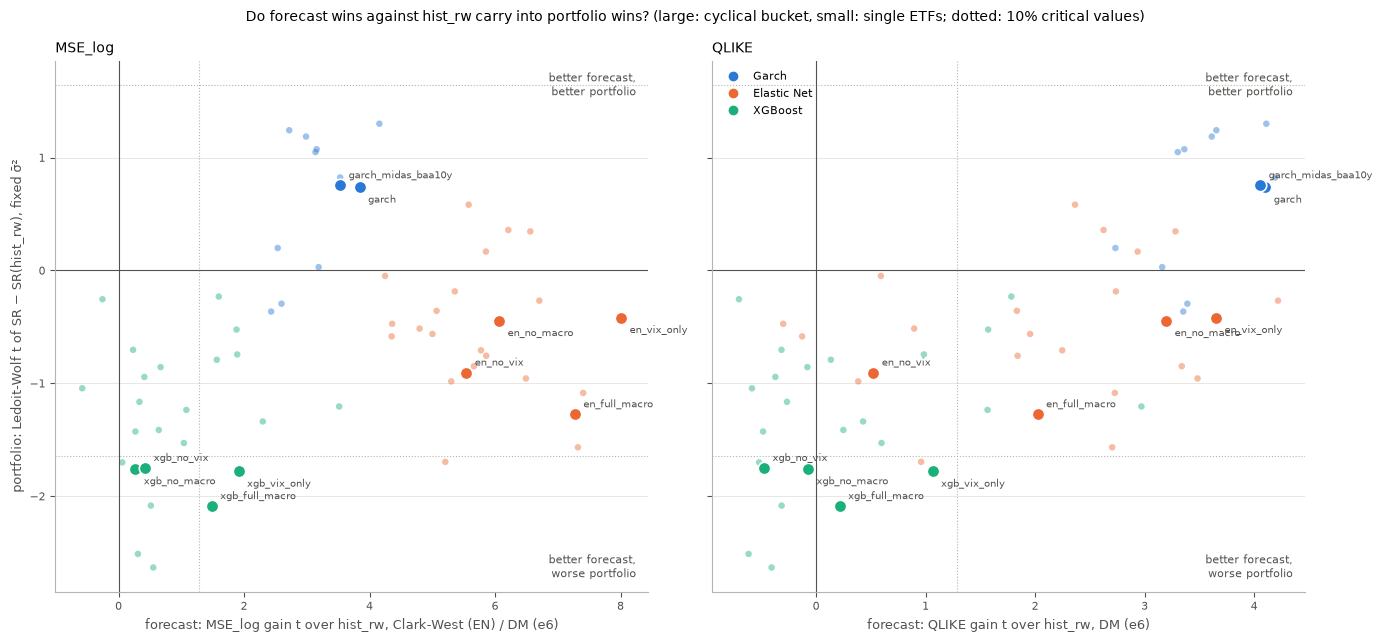

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
for ax, loss in zip(axes, ["MSE_log", "QLIKE"]):
    for i, m in enumerate(MODELS):
        pts = link.loc[m]
        ax.scatter(pts.loc[TICKERS, f"{loss} t"], pts.loc[TICKERS, "LW t"], s=22, color=color(m), alpha=0.45,
                   edgecolor="none")
        ax.scatter(pts.at["Cyclical", f"{loss} t"], pts.at["Cyclical", "LW t"], s=80, color=color(m),
                   edgecolor="white", linewidth=1.2, zorder=3)
        ax.annotate(m, (pts.at["Cyclical", f"{loss} t"], pts.at["Cyclical", "LW t"]),
                    xytext=(6, 5 if i % 2 else -11), textcoords="offset points", fontsize=7, color=TEXT_SECONDARY)
    ax.axvline(1.282, color="#b5b4ad", linewidth=0.8, linestyle=":")   # one-sided 10%
    for v in (-1.645, 1.645):                                           # two-sided 10%
        ax.axhline(v, color="#b5b4ad", linewidth=0.8, linestyle=":")
    ax.axhline(0, color="#52514e", linewidth=0.8)
    ax.axvline(0, color="#52514e", linewidth=0.8)
    corner = dict(transform=ax.transAxes, fontsize=8, color=TEXT_SECONDARY)
    ax.text(0.98, 0.98, "better forecast,\nbetter portfolio", ha="right", va="top", **corner)
    ax.text(0.98, 0.02, "better forecast,\nworse portfolio", ha="right", va="bottom", **corner)
    tests = "Clark-West (EN) / DM" if loss == "MSE_log" else "DM"
    ax.set_xlabel(f"forecast: {loss} gain t over {BENCHMARK}, {tests} (e6)", fontsize=9, color=TEXT_SECONDARY)
    ax.set_title(f"{loss}", fontsize=10, loc="left")
    style_axis(ax)
axes[0].set_ylabel(f"portfolio: Ledoit-Wolf t of SR − SR({BENCHMARK}), {MAIN_SPEC} σ̄²", fontsize=9,
                   color=TEXT_SECONDARY)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=c, label=f) for f, c in FAMILY_COLORS.items()]
axes[1].legend(handles=handles, fontsize=8, frameon=False, loc="upper left")
fig.suptitle(f"Do forecast wins against {BENCHMARK} carry into portfolio wins? "
             "(large: cyclical bucket, small: single ETFs; dotted: 10% critical values)", fontsize=10)
fig.tight_layout()
plt.show()

# 2 Ranks: do the best forecasters build the best portfolios?

All eleven models, `hist_rw` included, ranked by forecast accuracy (mean QLIKE from e6; QLIKE
scores the level forecast the weights use) and by the Sharpe ratio of the managed portfolio. If
forecast wins carried over, the two rankings would line up: the lines in the plot would be flat
and ρ close to 1. With eleven models, ρ is descriptive rather than a test.

In [31]:
loss_tbl = {loss: e6_losses[loss].unstack("ETF").loc[VARIANTS, UNITS] for loss in ["QLIKE", "MSE_log"]}
sharpe_tbl = etf_sr["SR_managed"].unstack("ETF").loc[VARIANTS, TICKERS]
sharpe_tbl["Cyclical"] = bucket_sr.loc[VARIANTS, "ann_sharpe"]

bucket_rank = pd.DataFrame({
    "family": [FAMILY[m] for m in VARIANTS],
    "QLIKE": loss_tbl["QLIKE"]["Cyclical"],
    "forecast rank": loss_tbl["QLIKE"]["Cyclical"].rank().astype(int),
    "SR": sharpe_tbl["Cyclical"],
    "portfolio rank": sharpe_tbl["Cyclical"].rank(ascending=False).astype(int),
}, index=pd.Index(VARIANTS, name="model"))
bucket_rank["rank change"] = bucket_rank["forecast rank"] - bucket_rank["portfolio rank"]
bucket_rank = bucket_rank.sort_values("forecast rank")


def rank_summary(loss):
    q, sr = loss_tbl[loss], sharpe_tbl
    best_fc = q.idxmin()
    return pd.DataFrame({
        "spearman_rho": pd.Series({u: (-q[u]).corr(sr[u], method="spearman") for u in UNITS}),
        "best_forecast_model": best_fc,
        "best_portfolio_model": sr.idxmax(),
        "same_model": best_fc == sr.idxmax(),
        "SR_of_best_forecast_model": [sr.at[m, u] for u, m in best_fc.items()],
        "SR_of_best_portfolio_model": sr.max(),
        f"SR_of_{BENCHMARK}": sr.loc[BENCHMARK],
    }).rename_axis("unit")


ranks = rank_summary("QLIKE")
print("Cyclical bucket, ordered by forecast rank (rank change > 0: the portfolio ranks higher than the forecast)")
display(bucket_rank)
print("Per unit, ranked by QLIKE:")
display(ranks)
print("Spearman ρ between forecast accuracy and Sharpe ratio, by loss:")
display(pd.DataFrame({f"ρ ({loss})": rank_summary(loss)["spearman_rho"] for loss in ["QLIKE", "MSE_log"]}).T)

Cyclical bucket, ordered by forecast rank (rank change > 0: the portfolio ranks higher than the forecast)


,family,QLIKE,forecast rank,SR,portfolio rank,rank change
model,,,,,,
garch,Garch,0.264,1,0.497,2,-1
garch_midas_baa10y,Garch,0.268,2,0.499,1,1
en_vix_only,Elastic Net,0.291,3,0.451,5,-2
en_full_macro,Elastic Net,0.325,4,0.399,7,-3
en_no_macro,Elastic Net,0.327,5,0.454,4,1
xgb_vix_only,XGBoost,0.358,6,0.351,9,-3
en_no_vix,Elastic Net,0.380,7,0.416,6,1
xgb_full_macro,XGBoost,0.392,8,0.310,11,-3
hist_rw,Historical,0.406,9,0.468,3,6


Per unit, ranked by QLIKE:


,spearman_rho,best_forecast_model,best_portfolio_model,same_model,SR_of_best_forecast_model,SR_of_best_portfolio_model,SR_of_hist_rw
unit,,,,,,,
XLB,0.745,garch_midas_baa10y,garch_midas_baa10y,True,0.234,0.234,0.176
XLE,0.909,garch,garch_midas_baa10y,False,0.120,0.127,0.119
XLF,0.718,garch,garch,True,0.596,0.596,0.522
XLI,0.473,garch,garch,True,0.606,0.606,0.527
XLY,0.391,garch,hist_rw,False,0.807,0.822,0.822
Cyclical,0.655,garch,garch_midas_baa10y,False,0.497,0.499,0.468


Spearman ρ between forecast accuracy and Sharpe ratio, by loss:


unit,XLB,XLE,XLF,XLI,XLY,Cyclical
ρ (QLIKE),0.745,0.909,0.718,0.473,0.391,0.655
ρ (MSE_log),0.400,0.500,0.555,-0.018,0.318,0.400


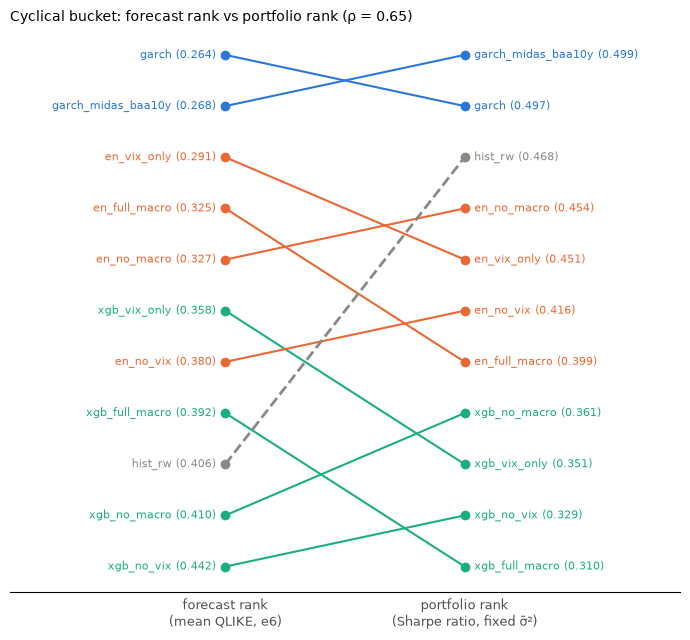

In [32]:
fig, ax = plt.subplots(figsize=(7, 6.5))
n = len(VARIANTS)
for m, r in bucket_rank.iterrows():
    c = color(m)
    ax.plot([0, 1], [r["forecast rank"], r["portfolio rank"]], color=c, linewidth=2 if m == BENCHMARK else 1.5,
            linestyle="--" if m == BENCHMARK else "-", marker="o")
    ax.text(-0.04, r["forecast rank"], f"{m} ({r['QLIKE']:.3f})", ha="right", va="center", fontsize=8, color=c)
    ax.text(1.04, r["portfolio rank"], f"{m} ({r['SR']:.3f})", ha="left", va="center", fontsize=8, color=c)
ax.set_xlim(-0.9, 1.9)
ax.set_ylim(n + 0.5, 0.5)
ax.set_xticks([0, 1], ["forecast rank\n(mean QLIKE, e6)", f"portfolio rank\n(Sharpe ratio, {MAIN_SPEC} σ̄²)"])
ax.set_yticks([])
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(colors=TEXT_SECONDARY, labelsize=9, length=0)
ax.set_title(f"Cyclical bucket: forecast rank vs portfolio rank (ρ = {ranks.at['Cyclical', 'spearman_rho']:.2f})",
             fontsize=10, loc="left")
fig.tight_layout()
plt.show()

# 3 Why forecast gains do or do not carry through

Three mechanisms can separate a forecast result from a portfolio result. The diagnostics use the
forecasts and realised variance from the forecast files, as e6 does, on the portfolio months.

## 3a Scale: errors the portfolio does not feel

The weight is σ̄² / σ̂², and each managed series is rescaled to its buy-and-hold volatility
afterwards. So if a model's forecasts for an ETF are all too high or too low by the same factor,
the weights for that ETF move by a constant, the rescale undoes it, and that ETF's managed Sharpe
ratio does not change (apart from months at the cap). QLIKE does penalise that bias.

To remove it, each model's forecasts for each ETF are multiplied by
k = mean(RV / σ̂²), the constant that minimises QLIKE (k > 1: the forecasts are too low on
average). The **scale-free QLIKE** measures only the timing information the weights use. k is
chosen over the evaluation sample, so this is a diagnostic, not a forecast. For the bucket the
invariance is only approximate, because a different k per ETF changes how the bucket is split
across ETFs.

In [33]:
forecasts_raw, _ = load_forecast_files(SELECTED)
fc_level = {v: forecast_wide(forecasts_raw[FAMILY[v]], v, "fc_level", TICKERS).loc[oos_first:oos_last]
            for v in VARIANTS}
rv = forecast_wide(forecasts_raw[FAMILY[BENCHMARK]], BENCHMARK, "actual_RV", TICKERS).loc[oos_first:oos_last]
oos_idx = rv.index
qlike_loss = {v: qlike(rv, fc_level[v]) for v in VARIANTS}
assert np.allclose([qlike_loss[v].to_numpy().mean() for v in VARIANTS], loss_tbl["QLIKE"]["Cyclical"]), \
    "QLIKE here does not match e6: rerun e6"

k = {v: (rv / fc_level[v]).mean() for v in VARIANTS}
qlike_sf = {v: qlike(rv, fc_level[v] * k[v]) for v in VARIANTS}
sf_tbl = pd.DataFrame({v: qlike_sf[v].mean() for v in VARIANTS}).T.loc[VARIANTS, TICKERS]
sf_tbl["Cyclical"] = sf_tbl[TICKERS].mean(axis=1)

print("k = mean(RV / forecast) per model and ETF (1 = unbiased in scale; > 1: forecasts too low)")
display(pd.DataFrame(k).T.loc[VARIANTS, TICKERS])

rho = pd.DataFrame({
    "ρ with QLIKE": ranks["spearman_rho"],
    "ρ with scale-free QLIKE": pd.Series({u: (-sf_tbl[u]).corr(sharpe_tbl[u], method="spearman") for u in UNITS}),
    "best scale-free forecast model": sf_tbl.idxmin(),
})
print("Rank correlation between forecast accuracy and Sharpe ratio, before and after removing scale:")
display(rho)

sf_gain = pd.Series({(m, u): sf_tbl.at[BENCHMARK, u] - sf_tbl.at[m, u] for m in MODELS for u in UNITS})
same_sf = np.sign(sf_gain.to_numpy()) == np.sign(link["ΔSR"].to_numpy())
print(f"Pairs where forecast and portfolio point the same way: "
      f"{link['same direction'].mean():.0%} with MSE_log, {same_sf.mean():.0%} with scale-free QLIKE")

k = mean(RV / forecast) per model and ETF (1 = unbiased in scale; > 1: forecasts too low)


etf,XLB,XLE,XLF,XLI,XLY
hist_rw,1.353,1.343,1.517,1.417,1.371
garch,1.032,1.133,1.087,1.091,1.072
garch_midas_baa10y,1.020,1.131,1.112,1.100,1.078
en_no_macro,1.025,1.072,1.020,1.095,1.082
en_no_vix,1.034,0.999,1.075,1.159,1.098
en_vix_only,0.960,1.053,0.946,1.095,1.113
en_full_macro,0.989,0.989,0.973,1.096,1.050
xgb_no_macro,1.068,1.127,1.099,1.064,1.200
xgb_no_vix,1.134,1.125,1.112,1.121,1.035
xgb_vix_only,1.092,1.120,1.017,1.103,1.085


Rank correlation between forecast accuracy and Sharpe ratio, before and after removing scale:


,ρ with QLIKE,ρ with scale-free QLIKE,best scale-free forecast model
XLB,0.745,0.755,garch_midas_baa10y
XLE,0.909,0.882,garch
XLF,0.718,0.836,garch
XLI,0.473,0.618,garch
XLY,0.391,0.555,garch
Cyclical,0.655,0.809,garch


Pairs where forecast and portfolio point the same way: 27% with MSE_log, 68% with scale-free QLIKE


## 3b How different is each portfolio from `hist_rw`'s?

A model can forecast more accurately and still give nearly the same weights as `hist_rw`, and then
the portfolios cannot differ much. Per model, under the fixed σ̄²: the mean absolute difference in
base weights from `hist_rw`, the correlation of the two managed buckets' returns, and the share of
ETF-months at the cap (where differences in the forecast do not reach the weight). The last two
columns repeat the bucket test statistics.

In [34]:
rw = portfolios[BENCHMARK]
spread = pd.DataFrame({
    m: {
        f"mean |w − w_{BENCHMARK}|": weight_distance(portfolios[m], rw),
        "return corr": portfolios[m]["managed"].corr(rw["managed"]),
        "% capped": pct_capped_pooled(portfolios[m]["weights_base"], K_CAP),
        f"% capped {BENCHMARK}": pct_capped_pooled(rw["weights_base"], K_CAP),
        "MSE_log t": bucket_link.at[m, "MSE_log t"],
        "LW t": bucket_link.at[m, "LW t"],
    }
    for m in MODELS
}).T.rename_axis("model")
spread

,mean |w − w_hist_rw|,return corr,% capped,% capped hist_rw,MSE_log t,LW t
model,,,,,,
garch,0.227,0.987,4.393,21.308,3.843,0.736
garch_midas_baa10y,0.234,0.986,4.299,21.308,3.534,0.755
en_no_macro,0.253,0.991,5.327,21.308,6.067,-0.447
en_no_vix,0.311,0.969,4.766,21.308,5.543,-0.905
en_vix_only,0.283,0.986,2.991,21.308,8.012,-0.419
en_full_macro,0.325,0.969,3.271,21.308,7.274,-1.275
xgb_no_macro,0.340,0.970,1.028,21.308,0.267,-1.760
xgb_no_vix,0.380,0.952,0.467,21.308,0.426,-1.750
xgb_vix_only,0.327,0.968,1.028,21.308,1.914,-1.782


## 3c Calm vs stress months

Macro-aware models should earn their keep around regime shifts. Months are split by the average
VIX of the forecast-origin month t, which is known when the weight for t+1 is set. **Stress**
months are those with VIX above its 75th percentile over the out-of-sample period. For each model
and regime: the QLIKE gain over `hist_rw` (% of `hist_rw`'s loss, bucket average) and the gap
between the two managed buckets' mean returns (% a year, positive: the model earned more). With
only a quarter of the months in the stress group, this is descriptive.

In [35]:
vix_origin = load_vix_monthly().shift(1).reindex(oos_idx)   # VIX of month t, for holding month t+1
assert vix_origin.notna().all()
threshold = vix_origin.quantile(0.75)
stress = vix_origin > threshold
print(f"Stress: VIX above {threshold:.1f} ({stress.sum()} months); calm: {(~stress).sum()} months")

regime = {}
for m in MODELS:
    row = {}
    for name, mask in [("calm", ~stress), ("stress", stress)]:
        lm = qlike_loss[m].loc[mask].mean(axis=1).mean()
        lb = qlike_loss[BENCHMARK].loc[mask].mean(axis=1).mean()
        row[f"QLIKE gain % ({name})"] = (lb - lm) / lb * 100
        gap = (portfolios[m]["managed"] - rw["managed"]).loc[mask]
        row[f"return gap % p.a. ({name})"] = gap.mean() * 12 * 100
    regime[m] = row
regime = pd.DataFrame(regime).T.rename_axis("model")
regime

Stress: VIX above 22.5 (54 months); calm: 160 months


,QLIKE gain % (calm),return gap % p.a. (calm),QLIKE gain % (stress),return gap % p.a. (stress)
model,,,,
garch,37.127,0.203,23.715,1.606
garch_midas_baa10y,36.106,0.109,21.810,2.041
en_no_macro,23.406,-0.876,-2.153,1.498
en_no_vix,14.219,-1.541,-37.427,0.587
en_vix_only,32.661,-0.528,3.296,0.251
en_full_macro,29.413,-1.136,-33.346,-1.923
xgb_no_macro,11.821,-2.919,-74.471,0.466
xgb_no_vix,8.449,-3.443,-106.803,-0.438
xgb_vix_only,25.984,-1.809,-68.188,-3.588


## Save the tables

Written to `results/eval/`:

- `forecast_portfolio_link.csv`: the forecast (e6) and portfolio (02) results of every model
  against `hist_rw`, per unit;
- `rank_summary_<spec>.csv`: the rank analysis, with the scale-free ρ;
- `pair_diagnostics.csv`: weight distance, cap and calm/stress results per model against `hist_rw`.

In [36]:
EVAL_DIR.mkdir(parents=True, exist_ok=True)
link.to_csv(EVAL_DIR / "forecast_portfolio_link.csv")
ranks.join(rho[["ρ with scale-free QLIKE", "best scale-free forecast model"]]).to_csv(
    EVAL_DIR / f"rank_summary_{MAIN_SPEC}.csv")
spread.join(regime).to_csv(EVAL_DIR / "pair_diagnostics.csv")
print("Saved to", EVAL_DIR.resolve())

Saved to C:\Documents\NUS\Y4S1\DSE4101\dse4101capstone_project\models\portfolio_construction\results\eval
